In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import pandas as pd
from PIL import Image, ImageOps, ImageDraw
import matplotlib.pyplot as plt

BASE_DIR = "/content/drive/MyDrive/Chattogram_Landmark_Dataset"

META_PATH = os.path.join(
    BASE_DIR,
    "03_candidates",
    "clean_candidate_metadata.csv"
)

clean_df = pd.read_csv(META_PATH)

print("Total records:", len(clean_df))
print("Columns:", list(clean_df.columns))

Total records: 5275
Columns: ['landmark', 'district', 'filename', 'path', 'sha256', 'title', 'file_url', 'description_url', 'license', 'artist', 'width', 'height', 'status', 'phash']


In [ ]:
REVIEW_PATH = os.path.join(
    BASE_DIR,
    "04_review",
    "duplicate_analysis",
    "cross_class_contamination_review.csv"
)

cross_review = pd.read_csv(REVIEW_PATH)

print("Cross-class images:", len(cross_review))
print("Suspicious:", cross_review["suspicious_source"].sum())

Cross-class images: 421
Suspicious: 65


In [ ]:
suspicious_df = cross_review[
    cross_review["suspicious_source"] == True
].copy()

print("Suspicious images:", len(suspicious_df))

Suspicious images: 65


In [ ]:
CONTACT_DIR = os.path.join(
    BASE_DIR,
    "04_review",
    "contact_sheets"
)

os.makedirs(CONTACT_DIR, exist_ok=True)

THUMB_W = 220
THUMB_H = 180
LABEL_H = 55
COLS = 4

images_per_sheet = COLS * 4

print("Images per contact sheet:", images_per_sheet)

Images per contact sheet: 16


In [ ]:
from PIL import Image, ImageOps, ImageDraw, ImageFont

font = ImageFont.load_default()

for start in range(0, len(suspicious_df), images_per_sheet):

    batch = suspicious_df.iloc[
        start:start + images_per_sheet
    ]

    rows = (len(batch) + COLS - 1) // COLS

    sheet = Image.new(
        "RGB",
        (
            COLS * THUMB_W,
            rows * (THUMB_H + LABEL_H)
        ),
        "white"
    )

    draw = ImageDraw.Draw(sheet)

    for position, (_, row) in enumerate(batch.iterrows()):

        try:
            img = Image.open(row["path"]).convert("RGB")
            img.thumbnail((THUMB_W - 10, THUMB_H - 10))

            x = (position % COLS) * THUMB_W
            y = (position // COLS) * (THUMB_H + LABEL_H)

            paste_x = x + (THUMB_W - img.width) // 2
            paste_y = y + (THUMB_H - img.height) // 2

            sheet.paste(img, (paste_x, paste_y))

            label = (
                f"{row['landmark']}\n"
                f"{row['filename'][:30]}"
            )

            draw.text(
                (x + 5, y + THUMB_H + 3),
                label,
                fill="black",
                font=font
            )

        except Exception as e:
            print(
                "Could not load:",
                row["path"],
                "|",
                e
            )

    sheet_path = os.path.join(
        CONTACT_DIR,
        f"suspicious_{start//images_per_sheet + 1:02d}.jpg"
    )

    sheet.save(
        sheet_path,
        quality=90
    )

    print("Saved:", sheet_path)

Could not load: /content/drive/MyDrive/Chattogram_Landmark_Dataset/03_candidates/Alutila_Cave/0033_File_Small_Area_Atlas_of_Bangladesh_-_Khagrachhari_Zila.pdf.jpg | [Errno 2] No such file or directory: '/content/drive/MyDrive/Chattogram_Landmark_Dataset/03_candidates/Alutila_Cave/0033_File_Small_Area_Atlas_of_Bangladesh_-_Khagrachhari_Zila.pdf.jpg'
Could not load: /content/drive/MyDrive/Chattogram_Landmark_Dataset/03_candidates/Anderson_Canal/0012_File_United_States_Civil_Aircraft_Register_Jan_1978_Vol_1.pdf.jpg | [Errno 2] No such file or directory: '/content/drive/MyDrive/Chattogram_Landmark_Dataset/03_candidates/Anderson_Canal/0012_File_United_States_Civil_Aircraft_Register_Jan_1978_Vol_1.pdf.jpg'
Could not load: /content/drive/MyDrive/Chattogram_Landmark_Dataset/03_candidates/Banshbaria_Beach/0045_File_Small_Area_Atlas_of_Bangladesh_-_Bagerhat_Zila.pdf.jpg | [Errno 2] No such file or directory: '/content/drive/MyDrive/Chattogram_Landmark_Dataset/03_candidates/Banshbaria_Beach/0045_

Contact sheets found: 5

suspicious_01.jpg


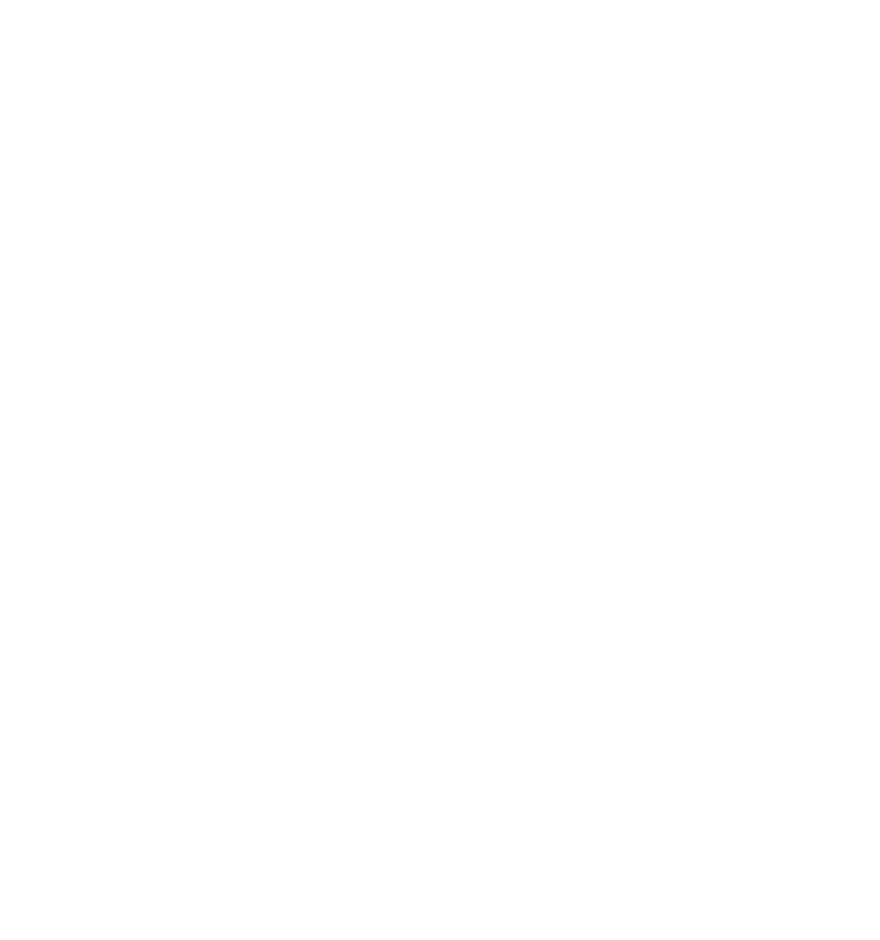


suspicious_02.jpg


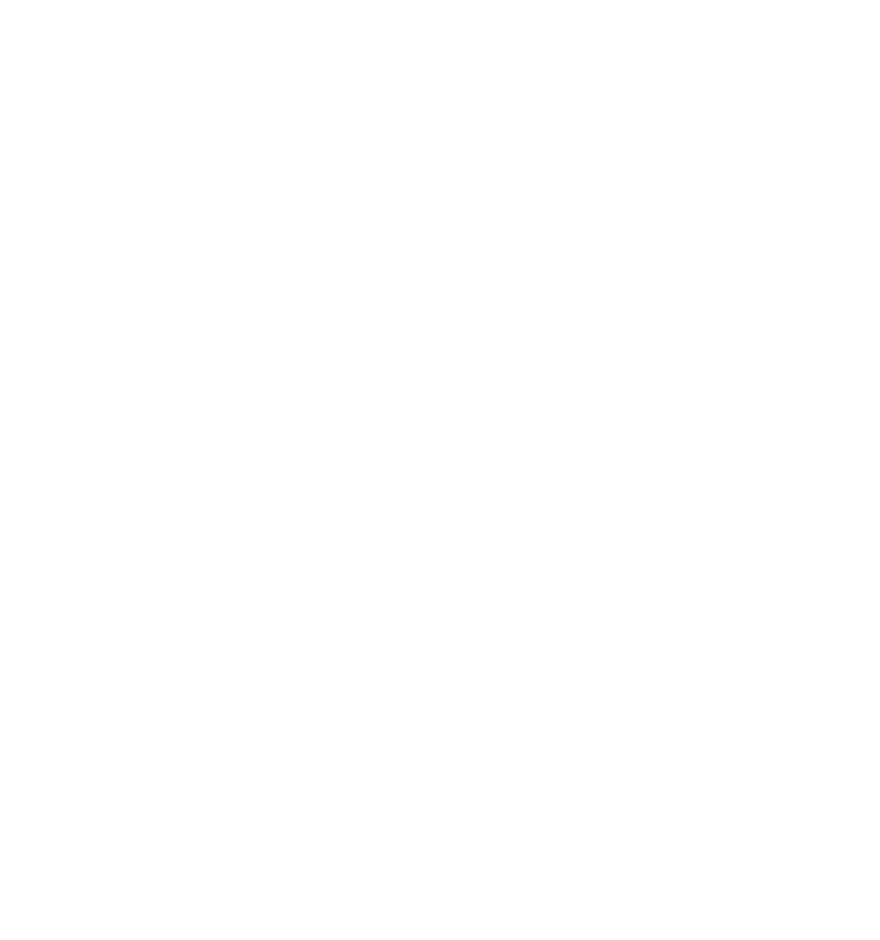


suspicious_03.jpg


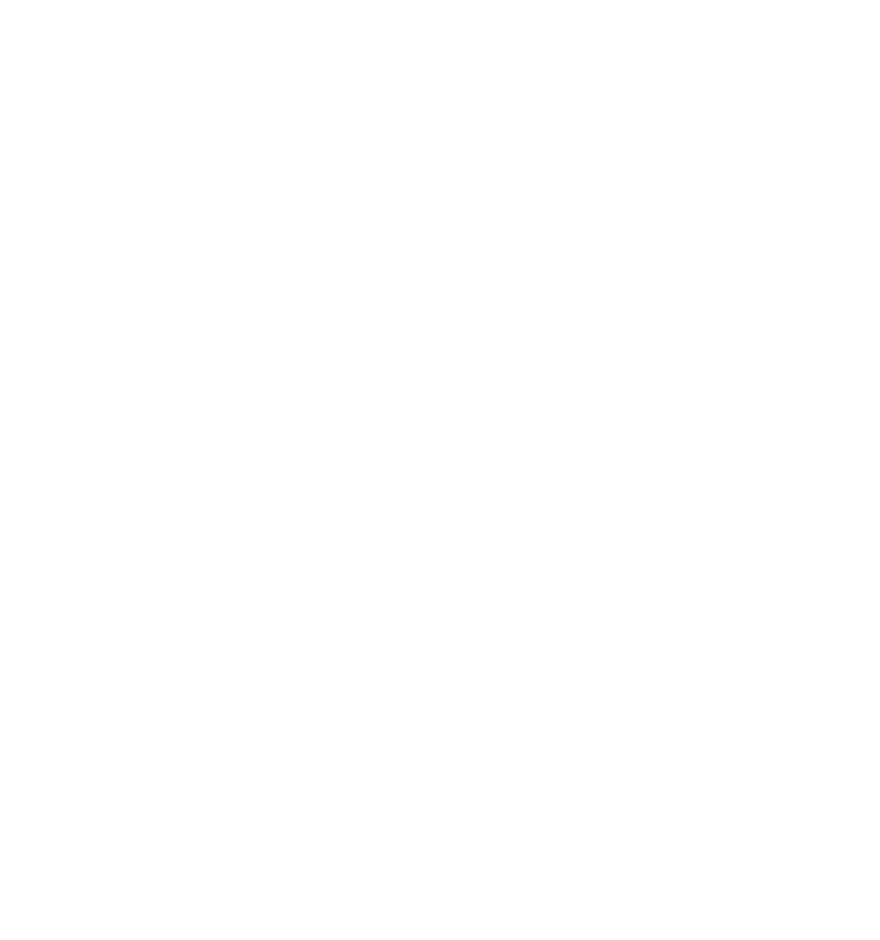


suspicious_04.jpg


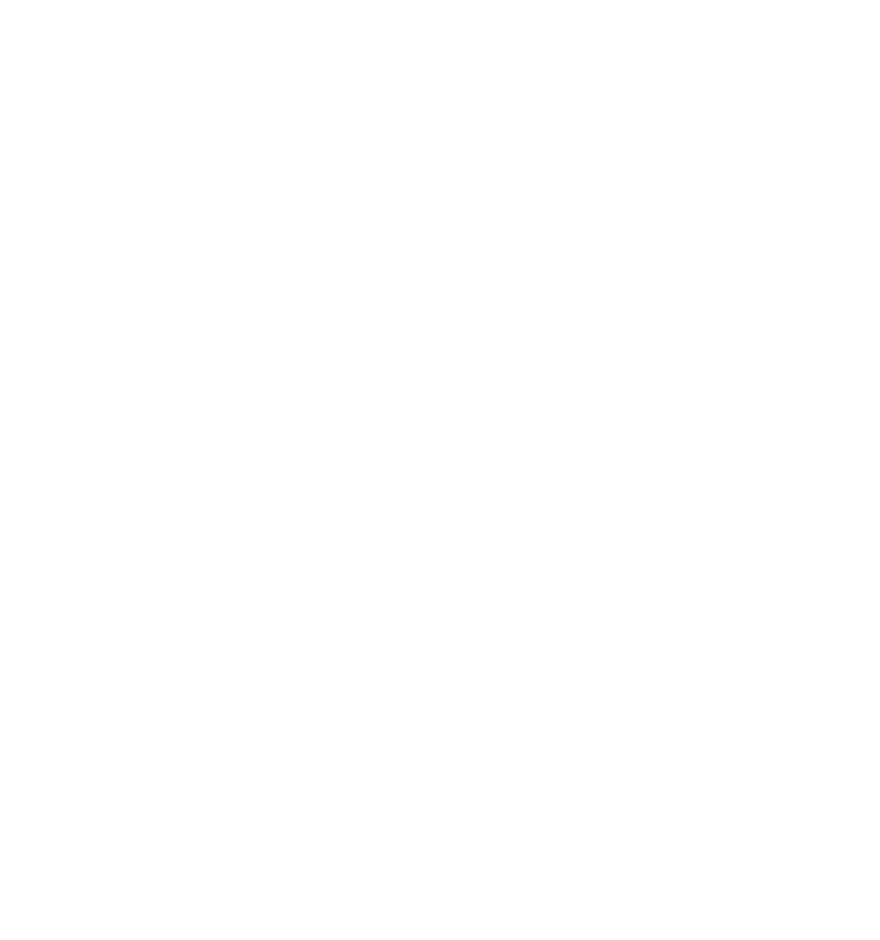


suspicious_05.jpg


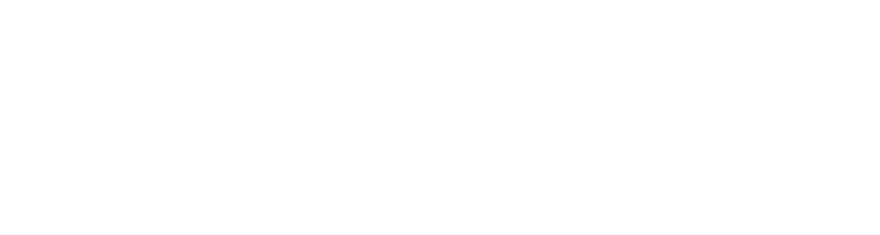

In [ ]:
import glob

sheet_paths = sorted(
    glob.glob(
        os.path.join(
            CONTACT_DIR,
            "suspicious_*.jpg"
        )
    )
)

print("Contact sheets found:", len(sheet_paths))

for path in sheet_paths:
    print("\n" + os.path.basename(path))
    display(Image.open(path))

In [ ]:
import os

DRIVE_ROOT = "/content/drive/MyDrive/Chattogram_Landmark_Dataset"

matches = []

for root, dirs, files in os.walk(DRIVE_ROOT):
    for file in files:
        if "cross_class" in file.lower() or "contamination" in file.lower():
            matches.append(os.path.join(root, file))

print("Found files:")
for path in matches:
    print(path)

if not matches:
    print("❌ No cross-class contamination CSV was found.")

Found files:
/content/drive/MyDrive/Chattogram_Landmark_Dataset/04_review/duplicate_analysis/cross_class_contamination_review.csv


In [ ]:
import pandas as pd

REVIEW_CSV = "/content/drive/MyDrive/Chattogram_Landmark_Dataset/04_review/duplicate_analysis/cross_class_contamination_review.csv"

review_df = pd.read_csv(REVIEW_CSV)

print("Total rows:", len(review_df))
print("\nColumns:")
print(review_df.columns.tolist())

print("\nSuspicious value counts:")
print(review_df["suspicious_source"].value_counts())

review_df.head()

Total rows: 421

Columns:
['landmark', 'district', 'filename', 'path', 'sha256', 'title', 'file_url', 'description_url', 'license', 'artist', 'width', 'height', 'status', 'phash', 'file_exists', 'phash_int', 'seg_0', 'seg_1', 'seg_2', 'seg_3', 'seg_4', 'seg_5', 'seg_6', 'suspicious_source']

Suspicious value counts:
suspicious_source
False    356
True      65
Name: count, dtype: int64


,landmark,district,filename,path,sha256,title,file_url,description_url,license,artist,...,file_exists,phash_int,seg_0,seg_1,seg_2,seg_3,seg_4,seg_5,seg_6,suspicious_source
0,Adinath_Temple,Coxs_Bazar,0001_File_Moheshkhali_adinath_temple01.jpg.jpg,/content/drive/MyDrive/Chattogram_Landmark_Dat...,b6d8492211fbab6204eef16b6544f77d55d2d155bf364d...,File:Moheshkhali adinath temple01.jpg,https://upload.wikimedia.org/wikipedia/commons...,https://commons.wikimedia.org/wiki/File:Mohesh...,Public domain,"<a href=""//commons.wikimedia.org/wiki/User:Mun...",...,True,15189565355102843523,131,25,223,206,211,97,331,False
1,Adinath_Temple,Coxs_Bazar,0002_File_Moheshkhali_adinath_temple02.jpg.jpg,/content/drive/MyDrive/Chattogram_Landmark_Dat...,e95d02b374ce6aa2cded17931b716d492a659988f8cf68...,File:Moheshkhali adinath temple02.jpg,https://upload.wikimedia.org/wikipedia/commons...,https://commons.wikimedia.org/wiki/File:Mohesh...,Public domain,"<a href=""//commons.wikimedia.org/wiki/User:Mun...",...,True,14566946251577439371,139,410,222,506,262,321,296,False
2,Adinath_Temple,Coxs_Bazar,0003_File_Moheshkhali00005.jpg.jpg,/content/drive/MyDrive/Chattogram_Landmark_Dat...,5f0c7d5f7f80e77f3b13ef851f0faaa744abdfa71d6220...,File:Moheshkhali00005.jpg,https://upload.wikimedia.org/wikipedia/commons...,https://commons.wikimedia.org/wiki/File:Mohesh...,CC BY-SA 3.0,"<a href=""//commons.wikimedia.org/wiki/User:Bel...",...,True,9662604678817525017,281,278,380,87,380,195,24,False
3,Adinath_Temple,Coxs_Bazar,0005_File_Adinath_temple_1.JPG.jpg,/content/drive/MyDrive/Chattogram_Landmark_Dat...,3b11c1a568b8b1d835c86e285ee0a4a905af53d80a868f...,File:Adinath temple 1.JPG,https://upload.wikimedia.org/wikipedia/commons...,https://commons.wikimedia.org/wiki/File:Adinat...,CC BY-SA 3.0,"<a href=""//commons.wikimedia.org/wiki/User:Tan...",...,True,18362665083449016988,156,321,284,338,169,170,507,False
4,Adinath_Temple,Coxs_Bazar,0006_File_Adinath_temple_2.JPG.jpg,/content/drive/MyDrive/Chattogram_Landmark_Dat...,9f555a2c57d120720910ab41094f9eb06ec82bafcb655b...,File:Adinath temple 2.JPG,https://upload.wikimedia.org/wikipedia/commons...,https://commons.wikimedia.org/wiki/File:Adinat...,CC BY-SA 3.0,"<a href=""//commons.wikimedia.org/wiki/User:Tan...",...,True,9772219150706078804,84,378,70,345,88,239,30,False


In [ ]:
suspicious_df = review_df[
    review_df["suspicious_source"] == True
].copy()

print("Suspicious images:", len(suspicious_df))

display(
    suspicious_df[
        ["landmark", "filename", "path", "suspicious_source"]
    ].head(20)
)

Suspicious images: 65


,landmark,filename,path,suspicious_source
47,Alutila_Cave,0033_File_Small_Area_Atlas_of_Bangladesh_-_Kha...,/content/drive/MyDrive/Chattogram_Landmark_Dat...,True
50,Anderson_Canal,0012_File_United_States_Civil_Aircraft_Registe...,/content/drive/MyDrive/Chattogram_Landmark_Dat...,True
51,Banshbaria_Beach,0045_File_Small_Area_Atlas_of_Bangladesh_-_Bag...,/content/drive/MyDrive/Chattogram_Landmark_Dat...,True
53,Bayazid_Bostami_Shrine,0048_File_Journal_of_the_Bombay_Natural_Histor...,/content/drive/MyDrive/Chattogram_Landmark_Dat...,True
57,Central_Railway_Building,0097_File_The_New_York_Times_1930-04-28-_Vol_7...,/content/drive/MyDrive/Chattogram_Landmark_Dat...,True
58,Central_Railway_Building,0104_File_A_Statistical_Account_of_Bengal_Vol_...,/content/drive/MyDrive/Chattogram_Landmark_Dat...,True
59,Chandpur_Boro_Station,0010_File_A_Handbook_for_Travellers_in_India_B...,/content/drive/MyDrive/Chattogram_Landmark_Dat...,True
60,Chandpur_Boro_Station,0012_File_Memoirs_of_the_Geological_Survey_of_...,/content/drive/MyDrive/Chattogram_Landmark_Dat...,True
61,Chandpur_Boro_Station,0013_File_Naldanga_and_the_Naldanga_Raj_family...,/content/drive/MyDrive/Chattogram_Landmark_Dat...,True
62,Chandpur_Boro_Station,0014_File_California_Digital_Library_IA_fiveye...,/content/drive/MyDrive/Chattogram_Landmark_Dat...,True


In [ ]:
import os

suspicious_df["file_exists_now"] = suspicious_df["path"].apply(
    lambda p: isinstance(p, str) and os.path.exists(p)
)

print("Files found:", suspicious_df["file_exists_now"].sum())
print("Files missing:", (~suspicious_df["file_exists_now"]).sum())

Files found: 0
Files missing: 65


In [ ]:
deleted = 0
failed = []

for path in suspicious_df.loc[
    suspicious_df["file_exists_now"], "path"
]:
    try:
        os.remove(path)
        deleted += 1
    except Exception as e:
        failed.append((path, str(e)))

print("===================================")
print("Deletion completed")
print("Deleted:", deleted)
print("Failed:", len(failed))
print("===================================")

if failed:
    print("\nFailed files:")
    for path, error in failed:
        print(path)
        print("Error:", error)

Deletion completed
Deleted: 0
Failed: 0


In [ ]:
remaining = []

for path in suspicious_df["path"]:
    if os.path.exists(path):
        remaining.append(path)

print("Suspicious images still present:", len(remaining))

if len(remaining) == 0:
    print("✓ All suspicious images have been removed.")
else:
    print("\nThese files still exist:")
    for path in remaining:
        print(path)

Suspicious images still present: 0
✓ All suspicious images have been removed.


In [ ]:
import pandas as pd
import os

METADATA_CSV = "/content/drive/MyDrive/Chattogram_Landmark_Dataset/03_candidates/clean_candidate_metadata.csv"

df = pd.read_csv(METADATA_CSV)

before = len(df)

# Keep only images that physically exist
df = df[
    df["path"].apply(
        lambda p: isinstance(p, str) and os.path.exists(p)
    )
].copy()

after = len(df)

print("Records before:", before)
print("Records after :", after)
print("Removed from metadata:", before - after)

# Save updated metadata
df.to_csv(METADATA_CSV, index=False)

print("\n✓ Metadata updated.")

Records before: 5275
Records after : 5275
Removed from metadata: 0

✓ Metadata updated.


In [ ]:
class_counts = (
    df.groupby(["district", "landmark"])
      .size()
      .reset_index(name="image_count")
      .sort_values(["district", "image_count"], ascending=[True, False])
)

display(class_counts)

,district,landmark,image_count
8,Bandarban,Nilgiri,110
3,Bandarban,Golden_Temple_Bandarban,107
7,Bandarban,Nilachal,105
1,Bandarban,Boga_Lake,101
2,Bandarban,Chimbuk_Hill,71
...,...,...,...
78,Rangamati,Shuvolong_Waterfall,31
72,Rangamati,Kaptai_Dam,15
77,Rangamati,Rangamati_Jum_Museum,13
75,Rangamati,Rajban_Vihara,7


In [ ]:
print("========================================")
print("CLASS AVAILABILITY")
print("========================================")

print("\nClasses with 40+ images:")
print((class_counts["image_count"] >= 40).sum())

print("\nClasses with 30–39 images:")
print(
    (
        (class_counts["image_count"] >= 30) &
        (class_counts["image_count"] <= 39)
    ).sum()
)

print("\nClasses with fewer than 30 images:")
print((class_counts["image_count"] < 30).sum())

print("\nTotal classes:")
print(len(class_counts))

CLASS AVAILABILITY

Classes with 40+ images:
49

Classes with 30–39 images:
9

Classes with fewer than 30 images:
22

Total classes:
80


In [ ]:
strong_classes = class_counts[
    class_counts["image_count"] >= 40
].copy()

acceptable_classes = class_counts[
    (class_counts["image_count"] >= 30) &
    (class_counts["image_count"] <= 39)
].copy()

insufficient_classes = class_counts[
    class_counts["image_count"] < 30
].copy()

print("========================================")
print("STRONG: 40+ images")
print("========================================")
display(strong_classes)

print("\n========================================")
print("ALREADY BALANCED: 30–39 images")
print("========================================")
display(acceptable_classes)

print("\n========================================")
print("INSUFFICIENT: <30 images")
print("========================================")
display(insufficient_classes)

STRONG: 40+ images


,district,landmark,image_count
8,Bandarban,Nilgiri,110
3,Bandarban,Golden_Temple_Bandarban,107
7,Bandarban,Nilachal,105
1,Bandarban,Boga_Lake,101
2,Bandarban,Chimbuk_Hill,71
12,Brahmanbaria,Haripur_Barendra_Bari,115
13,Brahmanbaria,Titas_River,104
15,Chandpur,Chandpur_Stadium,51
32,Chattogram,Ethnological_Museum,119
38,Chattogram,Patenga_Beach,119



ALREADY BALANCED: 30–39 images


,district,landmark,image_count
4,Bandarban,Keokradong,39
10,Brahmanbaria,Anderson_Canal,37
11,Brahmanbaria,Arifail_Mosque,31
31,Chattogram,Cheragi_Pahar,37
23,Chattogram,Chandanpura_Mosque,35
63,Khagrachhari,Alutila_Cave,33
69,Lakshmipur,Ramgati_Beach,37
70,Noakhali,Bajra_Shahi_Mosque,32
78,Rangamati,Shuvolong_Waterfall,31



INSUFFICIENT: <30 images


,district,landmark,image_count
5,Bandarban,Meghla_Tourist_Complex,28
0,Bandarban,Amiakhum,17
6,Bandarban,Nafakhum_Waterfall,16
9,Bandarban,Shoilo_Propat,4
16,Chandpur,Rupsha_Jamidar_Bari,21
14,Chandpur,Chandpur_Boro_Station,18
17,Chandpur,Three_Rivers_Mouth,13
37,Chattogram,Parki_Beach,12
47,Coxs_Bazar,Kutubdia_Lighthouse,18
50,Coxs_Bazar,Ramu_Buddhist_Temples,17
